# Supervised Learning: Random Forest Model

In this notebook, we build, tune, and evaluate a **Random Forest Classifier** to detect electricity theft using the 22 inputs (13 engineered features and PC2 to PC10).

### Methodology & Validation Design:
1. **Hyperparameter Tuning**: 5-fold cross-validation grid search performed exclusively on the 28,179 training customers using predefined stratified folds.
2. **Leakage-Free Threshold Selection**: To prevent data leakage, the classification threshold (`cut`) is selected strictly on the training set by maximizing F1 on **out-of-fold (OOF) training probabilities**. The test set remains completely unseen during threshold selection.
3. **Held-Out Test Evaluation**: The model is evaluated once on the 12,077 held-out test customers using the fixed training cut.
4. **Interpretability & Operational Audit**: Feature importance analysis via Mean Decrease in Impurity (MDI), diagnostic ROC/PR curves, and an operational top-5% riskiest customer audit.

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import PredefinedSplit, GridSearchCV, cross_val_predict
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, precision_recall_curve,
    confusion_matrix
)
from sklearn.base import clone

# Suppress repetitive joblib/parallel warnings
warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')

from pipeline import get_inputs_ready, DATA_DIR, NOTEBOOK_DIR

get_inputs_ready('random_forest_model.ipynb')

FIGURES_DIR = os.path.join(NOTEBOOK_DIR, '..', 'figures')
RESULTS_DIR = os.path.join(NOTEBOOK_DIR, '..', 'results')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment and dependencies verified successfully.")

All inputs for random_forest_model.ipynb are in place.
Environment and dependencies verified successfully.


## 1. Load Features and Predefined Split Folds
We load the 22 input features defined in `feature_info.json` and partition the dataset into training (28,179 customers) and test (12,077 customers) sets using the pre-assigned stratified folds.

In [2]:
# 1. Load feature definitions
with open(os.path.join(DATA_DIR, 'feature_info.json')) as f:
    feature_info = json.load(f)
model_inputs = feature_info['model_inputs']

# 2. Load dataset
data = pd.read_csv(os.path.join(DATA_DIR, 'features.csv'))

is_train = (data['split'] == 'train').values
is_test = (data['split'] == 'test').values

X_train = data.loc[is_train, model_inputs].values
y_train = data.loc[is_train, 'FLAG'].values
train_folds = data.loc[is_train, 'fold'].values

X_test = data.loc[is_test, model_inputs].values
y_test = data.loc[is_test, 'FLAG'].values
test_cons = data.loc[is_test, 'CONS_NO'].values

print(f"Loaded {len(model_inputs)} model input features:\n{model_inputs}\n")
print(f"Train set: {X_train.shape[0]:,} customers (Theft count: {y_train.sum():,})")
print(f"Test set:  {X_test.shape[0]:,} customers (Theft count: {y_test.sum():,})")

Loaded 22 model input features:
['mean_kwh', 'std_kwh', 'cv_kwh', 'zero_share', 'missing_share', 'longest_missing_run', 'trend_slope', 'trend_rel', 'n_sudden_drops', 'max_monthly_drop', 'weekend_share', 'dow_variation', 'weekly_autocorr', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10']

Train set: 28,179 customers (Theft count: 2,505)
Test set:  12,077 customers (Theft count: 1,074)


## 2. Hyperparameter Tuning via 5-Fold Cross-Validation
We perform a grid search over tree depth, split requirements, number of estimators, and class weighting (`balanced` vs `balanced_subsample`) to handle the ~10:1 class imbalance exclusively on the training set.

In [3]:
ps = PredefinedSplit(test_fold=train_folds)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 14, 18, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample']
}

base_rf = RandomForestClassifier(random_state=42, n_jobs=1)

grid_search = GridSearchCV(
    estimator=base_rf,
    param_grid=param_grid,
    cv=ps,
    scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'},
    refit='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("Starting 5-fold CV grid search on the training set...")
grid_search.fit(X_train, y_train)

best_i = grid_search.best_index_
cv_roc_mean = float(grid_search.cv_results_['mean_test_roc_auc'][best_i])
cv_pr_mean = float(grid_search.cv_results_['mean_test_pr_auc'][best_i])
cv_roc_per_fold = []
for k in range(5):
    cv_roc_per_fold.append(float(grid_search.cv_results_['split' + str(k) + '_test_roc_auc'][best_i]))

print(f"\nBest CV ROC-AUC: {cv_roc_mean:.4f}   CV PR-AUC: {cv_pr_mean:.4f}")
print(f"Per fold ROC-AUC: {np.round(cv_roc_per_fold, 4)}")
print("Best settings:")
for param, val in grid_search.best_params_.items():
    print(f" - {param}: {val}")

best_rf = grid_search.best_estimator_

Starting 5-fold CV grid search on the training set...
Fitting 5 folds for each of 48 candidates, totalling 240 fits



Best CV ROC-AUC: 0.7993   CV PR-AUC: 0.3725
Per fold ROC-AUC: [0.8064 0.795  0.7965 0.7989 0.7997]
Best settings:
 - class_weight: balanced
 - max_depth: None
 - min_samples_split: 5
 - n_estimators: 200


## 3. Out-of-Fold (OOF) Evaluation & Leak-Free Decision Cut Selection
**Preventing Test Leakage**: The classification cut is selected strictly on the training set. We generate out-of-fold predicted probabilities across the 5 cross-validation folds and pick the threshold that maximizes the F1-score for the theft class. The test set remains untouched here.

In [4]:
# Every training customer gets a score from a forest that did not see them in training
oof_probs = cross_val_predict(clone(best_rf), X_train, y_train, cv=ps,
                              method='predict_proba', n_jobs=-1)[:, 1]

oof_precision, oof_recall, oof_cuts = precision_recall_curve(y_train, oof_probs)
oof_precision = oof_precision[:-1]     # the last point has no cut attached to it
oof_recall = oof_recall[:-1]
oof_f1 = 2 * oof_precision * oof_recall / (oof_precision + oof_recall + 1e-10)
best_threshold = float(oof_cuts[np.argmax(oof_f1)])

print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_train, oof_probs):.4f}")
print(f"Cut with the best F1 on training customers: {best_threshold:.4f} (F1 {oof_f1.max():.4f})")

Out-of-fold ROC-AUC: 0.7991
Cut with the best F1 on training customers: 0.3935 (F1 0.3901)


## 4. Test Set Evaluation (Unseen 12,077 Customers)
We evaluate the held-out test set using the fixed threshold selected on the training set in Section 3, and compute confusion matrix metrics and balanced accuracy for the report.

In [5]:
# Predict probabilities on test set
test_probs = best_rf.predict_proba(X_test)[:, 1]

test_roc_auc = float(roc_auc_score(y_test, test_probs))
test_pr_auc = float(average_precision_score(y_test, test_probs))

# Apply the threshold chosen on the training customers only (best_threshold from Section 3)
test_preds = (test_probs >= best_threshold).astype(int)

# Compile metrics table
metrics_table = pd.DataFrame({
    'Metric': ['ROC-AUC', 'PR-AUC', 'Decision Cut (from Train OOF)', 'Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value': [
        round(test_roc_auc, 4),
        round(test_pr_auc, 4),
        round(best_threshold, 4),
        round(accuracy_score(y_test, test_preds), 4),
        round(precision_score(y_test, test_preds), 4),
        round(recall_score(y_test, test_preds), 4),
        round(f1_score(y_test, test_preds), 4)
    ]
})

print("=== RANDOM FOREST TEST METRICS TABLE ===")
print(metrics_table.to_string(index=False))

# Confusion matrix and balanced accuracy for the report
tn, fp, fn, tp = confusion_matrix(y_test, test_preds, labels=[0, 1]).ravel()
test_bal_acc = float(balanced_accuracy_score(y_test, test_preds))
baseline_acc = float(1 - y_test.mean())
print(f"\nBalanced accuracy: {test_bal_acc:.4f}")
print(f"Accuracy if every customer is called normal: {baseline_acc:.4f}")
print(f"TP {tp}  FP {fp}  FN {fn}  TN {tn}")

=== RANDOM FOREST TEST METRICS TABLE ===
                       Metric  Value
                      ROC-AUC 0.8015
                       PR-AUC 0.3853
Decision Cut (from Train OOF) 0.3935
                     Accuracy 0.8873
                    Precision 0.3768
                       Recall 0.4088
                     F1-Score 0.3921

Balanced accuracy: 0.6714
Accuracy if every customer is called normal: 0.9111
TP 439  FP 726  FN 635  TN 10277


## 5. Feature Importance Analysis
We analyze feature importances using Mean Decrease in Impurity (MDI) across all decision trees in the ensemble.

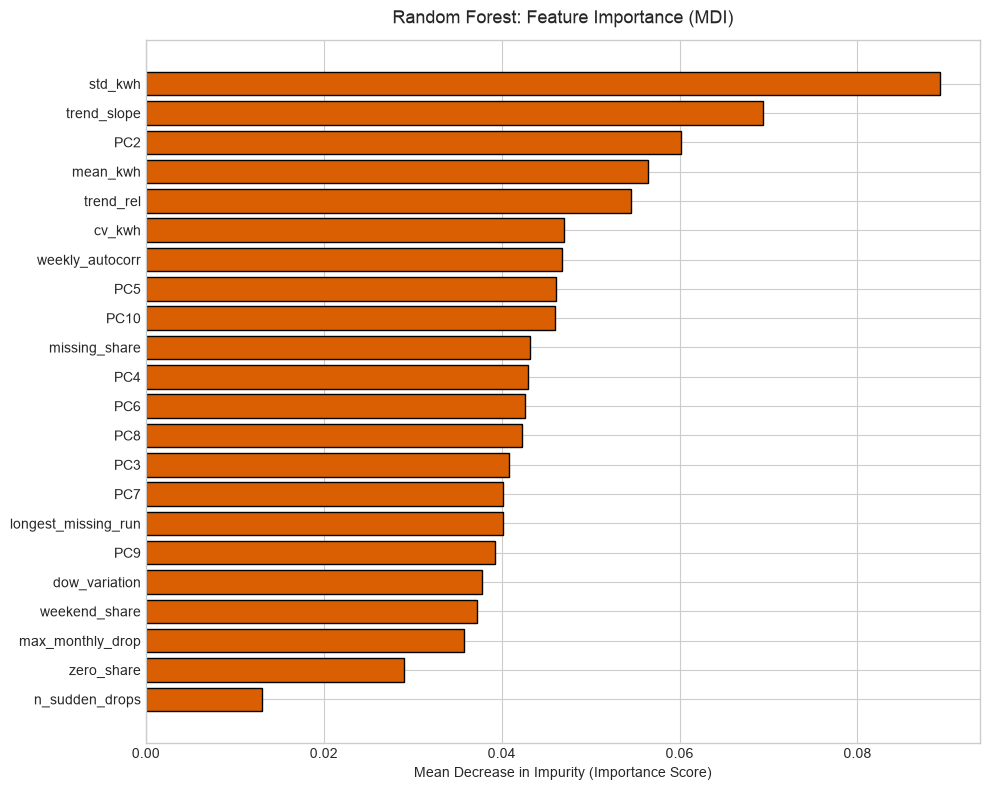

Saved feature importance figure to: /Users/dinuwan/Masters/Lec/Fundementals of ML/electricity-theft-detection/notebooks/../figures/step6_rf_feature_importance.png


In [6]:
importances = best_rf.feature_importances_
feat_df = pd.DataFrame({
    'Feature': model_inputs,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(feat_df['Feature'], feat_df['Importance'], color='#d95f02', edgecolor='black')
plt.title('Random Forest: Feature Importance (MDI)', fontsize=13, pad=12)
plt.xlabel('Mean Decrease in Impurity (Importance Score)')
plt.tight_layout()

# Save figure for report
fig_path = os.path.join(FIGURES_DIR, 'step6_rf_feature_importance.png')
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved feature importance figure to: {fig_path}")

## 6. Diagnostic Performance Curves
We plot the ROC Curve (True Positive Rate vs False Positive Rate) and the Precision-Recall Curve on the held-out test set.

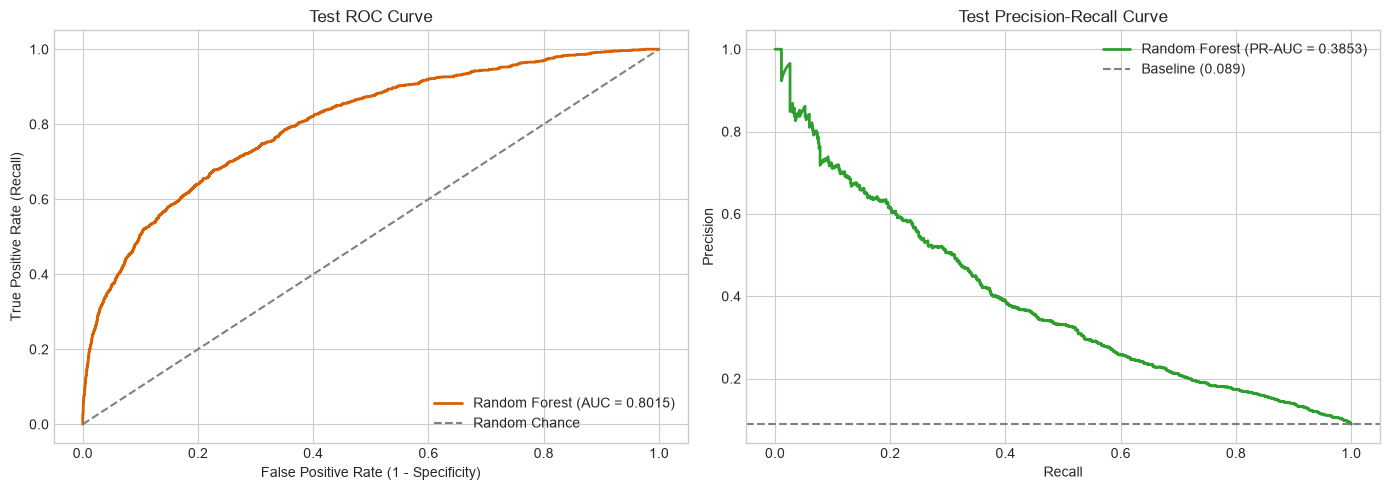

Saved diagnostic curves to: /Users/dinuwan/Masters/Lec/Fundementals of ML/electricity-theft-detection/notebooks/../figures/step6_rf_curves.png


In [7]:
fpr, tpr, _ = roc_curve(y_test, test_probs)
test_precision_curve, test_recall_curve, _ = precision_recall_curve(y_test, test_probs)
baseline_prevalence = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ROC Curve
axes[0].plot(fpr, tpr, color='#d95f02', lw=2, label=f'Random Forest (AUC = {test_roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Chance')
axes[0].set_title('Test ROC Curve', fontsize=12)
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# 2. PR Curve
axes[1].plot(test_recall_curve, test_precision_curve, color='#2ca02c', lw=2, label=f'Random Forest (PR-AUC = {test_pr_auc:.4f})')
axes[1].axhline(y=baseline_prevalence, color='gray', linestyle='--', label=f'Baseline ({baseline_prevalence:.3f})')
axes[1].set_title('Test Precision-Recall Curve', fontsize=12)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

plt.tight_layout()
fig_curves_path = os.path.join(FIGURES_DIR, 'step6_rf_curves.png')
plt.savefig(fig_curves_path, dpi=300)
plt.show()
print(f"Saved diagnostic curves to: {fig_curves_path}")

## 7. Operational Audit: Top 5% Riskiest Customers
Power utilities operate under finite field inspection budgets. We simulate inspecting the top 5% highest-risk accounts ranked by predicted theft probability and evaluate detection capture rate and efficiency lift.

In [8]:
# Number of accounts representing top 5% of test population
top5_cutoff = int(np.ceil(len(y_test) * 0.05))

# Rank test customers by predicted probability descending
ranked_indices = np.argsort(-test_probs)
top5_indices = ranked_indices[:top5_cutoff]

# Count actual thieves caught in top 5%
thieves_in_top5 = int(y_test[top5_indices].sum())
total_thieves = int(y_test.sum())
capture_rate = (thieves_in_top5 / total_thieves) * 100
lift = capture_rate / 5.0  # 5% inspection baseline

print("=== TOP 5% RISKIEST CUSTOMERS AUDIT ===")
print(f"Total Test Customers:             {len(y_test):,}")
print(f"Total Actual Thieves in Test:     {total_thieves:,}")
print(f"Top 5% Accounts Audited:          {top5_cutoff:,}")
print(f"Actual Thieves Caught in Top 5%:  {thieves_in_top5:,}")
print(f"Capture Rate (Sensitivity):       {capture_rate:.2f}% of all thieves")
print(f"Efficiency Lift:                  {lift:.2f}x better than random inspections")

=== TOP 5% RISKIEST CUSTOMERS AUDIT ===
Total Test Customers:             12,077
Total Actual Thieves in Test:     1,074
Top 5% Accounts Audited:          604
Actual Thieves Caught in Top 5%:  313
Capture Rate (Sensitivity):       29.14% of all thieves
Efficiency Lift:                  5.83x better than random inspections


## 8. Export Test Predictions and Model Metadata
We export `rf_test_predictions.csv` and `rf_info.json` in the exact schema needed for McNemar's test and the joint comparison notebook.

In [9]:
# 1. Save predictions CSV for McNemar test
rf_predictions = pd.DataFrame({
    'CONS_NO': test_cons,
    'FLAG': y_test,
    'rf_score': test_probs,
    'rf_pred': test_preds
})

pred_path = os.path.join(DATA_DIR, 'rf_test_predictions.csv')
rf_predictions.to_csv(pred_path, index=False)
print(f"Saved test predictions to: {pred_path}")

# 2. Save metadata JSON
rf_info = {
    'inputs': model_inputs,
    'best_params': grid_search.best_params_,
    'cut': float(best_threshold),
    'cut_rule': 'best F1 for theft class on out-of-fold training probabilities',
    'cv_roc_auc_mean': cv_roc_mean,
    'cv_roc_auc_per_fold': cv_roc_per_fold,
    'cv_pr_auc_mean': cv_pr_mean,
    'test_roc_auc': test_roc_auc,
    'test_pr_auc': test_pr_auc,
    'test_accuracy': float(accuracy_score(y_test, test_preds)),
    'test_balanced_accuracy': test_bal_acc,
    'test_baseline_accuracy_all_normal': baseline_acc,
    'test_precision': float(precision_score(y_test, test_preds)),
    'test_recall': float(recall_score(y_test, test_preds)),
    'test_f1': float(f1_score(y_test, test_preds)),
    'TP': int(tp),
    'FP': int(fp),
    'FN': int(fn),
    'TN': int(tn),
    'top5_audit': {
        'customers_audited': top5_cutoff,
        'thieves_caught': thieves_in_top5,
        'capture_rate_pct': float(capture_rate),
        'lift': float(lift)
    }
}

info_path = os.path.join(DATA_DIR, 'rf_info.json')
with open(info_path, 'w') as f:
    json.dump(rf_info, f, indent=2)

print(f"Saved model summary to: {info_path}")
print("\n[SUCCESS]: Random Forest training, evaluation, and test predictions complete.")

Saved test predictions to: /Users/dinuwan/Masters/Lec/Fundementals of ML/electricity-theft-detection/notebooks/../data/rf_test_predictions.csv
Saved model summary to: /Users/dinuwan/Masters/Lec/Fundementals of ML/electricity-theft-detection/notebooks/../data/rf_info.json

[SUCCESS]: Random Forest training, evaluation, and test predictions complete.
